# DA and the BWM LD1, within mice

Within each DA fiber, across its sessions: does a session's position on the **BWM LD1** (its projection into the
proficient 1-camera embedding, `3_nm_in_bwm_embedding`) go with how DA behaves in that session? Within-fiber, so
mouse-to-mouse differences (fiber placement, expression, the mouse) are out by construction.

- **Fibers**: VTA-DA and SNc-DA, ≥ 5 sessions, ephys + biased protocols (`ld1_neural.MIN_SESSIONS`). **VTA and SNc
  are analysed separately** (different projections, reward vs movement roles; the interaction test below shows they
  do differ here); pooled results are kept only as a secondary view.
- **DA measures** per fiber-session (`ld1_neural.py`): pre-stimulus baseline, stimulus response (all trials; and
  only trials whose first movement comes after the window), reward and error responses, reward on hard minus easy
  trials, and the movement couplings of `coupling_individuality` (partial β of still paw / whisking / licking, unique
  vigor and whisker R², per epoch).
- **Test**: correlation after removing each fiber's mean; p by permuting LD1 among a fiber's own sessions; BH FDR
  over the measures. Controls added step by step: recording day (linear, per fiber) and protocol; then the session's
  reaction time and accuracy (both LD1 correlates that DA is known to track); then quiescence wheel speed / the
  share of slow trials.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nm_projection as npj
import ld1_neural as L

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
emb, sc = npj.frame()
A = npj.project(emb, sc, protocol=None)
T = L.session_table(A, targets=('VTA-DA', 'SNc-DA'))
PH = ['baseline', 'stim', 'stim_slow', 'reward', 'error', 'reward_hard']
CP = [c for c in T if c.startswith(('β ', 'R² '))]
BASE = ('day', 'protocol')
display(T.groupby('target_NM').agg(sessions=('eid', 'size'), fibers=('fiber', 'nunique'), mice=('subject', 'nunique')))
T.groupby('fiber').agg(sessions=('eid', 'size'), LD1_sd=('LD1', 'std'), days=('day_n', lambda s: s.max() - s.min())).round(2)

,sessions,fibers,mice
target_NM,,,
SNc-DA,63,5,5
VTA-DA,135,5,5


,sessions,LD1_sd,days
fiber,,,
ZFM-03447 VTA,5,2.70,277
ZFM-04019 SNc,22,1.38,393
ZFM-04022 SNc,5,2.09,362
ZFM-08818 VTA,21,1.17,57
ZFM-08828 VTA,34,1.90,102
ZFM-09044 VTA,29,1.24,74
ZFM-09139 SNc,14,1.37,22
ZFM-09343 SNc-l,16,1.89,23
ZFM-09394 VTA-r,46,2.51,106


In [2]:
#%%
""" SANITY: within fiber, does session LD1 track the same session's behaviour? (wheel measures are partly
circular: the syllables contain wheel states; RT and accuracy are not) """
beh = ['log_reaction', 'correct', 'wheel_gate', 'paw_gate', 'wheel_speed_Quiescence', 'switches']
print('within-fiber r(LD1, recording day):',
      round(np.corrcoef(T['LD1'] - T.groupby('fiber')['LD1'].transform('mean'),
                        T['day_n'] - T.groupby('fiber')['day_n'].transform('mean'))[0, 1], 3))
L.within_fiber(T, beh, controls=BASE, n_perm=2000).round(3)

within-fiber r(LD1, recording day): 0.049


,measure,r,p,n_sessions,n_fibers,n_mice,q
0,log_reaction,-0.569,0.000,198,10,10,0.001
1,correct,0.205,0.013,198,10,10,0.016
2,wheel_gate,-0.538,0.000,198,10,10,0.001
3,paw_gate,-0.626,0.000,198,10,10,0.001
4,wheel_speed_Quiescence,0.518,0.000,198,10,10,0.001
5,switches,-0.041,0.599,197,10,10,0.599


In [3]:
#%%
""" MAIN, PER TARGET: LD1 vs the DA measures within VTA fibers and within SNc fibers, controls added step by step """
STEPS = {'day + protocol': BASE, '+ RT + accuracy': BASE + ('log_reaction', 'correct'),
         '+ quiescence wheel': BASE + ('log_reaction', 'correct', 'wheel_speed_Quiescence')}
PER = {tg: {k: L.within_fiber(T[T['target_NM'] == tg], PH + CP, controls=c, n_perm=5000).set_index('measure')
            for k, c in STEPS.items()} for tg in ['VTA-DA', 'SNc-DA']}
pd.concat({(tg, k): v[['r', 'q']] for tg, d in PER.items() for k, v in d.items()}, axis=1).round(3)

VTA-DA                                                                 SNc-DA                                                        
                          day + protocol        + RT + accuracy        + quiescence wheel        day + protocol        + RT + accuracy        + quiescence wheel       
                                       r      q               r      q                  r      q              r      q               r      q                  r      q
measure                                                                                                                                                                
baseline                          -0.301  0.005           0.074  0.521              0.148  0.230          0.068  0.923           0.123  0.819              0.116  0.831
stim                               0.500  0.001           0.256  0.023              0.125  0.362         -0.011  0.969           0.064  0.819              0.006  0.973
stim_slow                          0.326  0.001           0.131  0.323              0.068  0.605          0.006  0.969           0.077  0.819              0.033  0.973
reward                            -0.022  0.875          -0.162  0.174             -0.149  0.230         -0.064  0.923          -0.089  0.819             -0.112  0.831
error                             -0.374  0.001          -0.056  0.600             -0.028  0.754          0.030  0.969           0.026  0.859              0.047  0.973
reward_hard                       -0.129  0.268           0.081  0.521              0.114  0.371         -0.081  0.923          -0.112  0.819             -0.170  0.788
β paw 0 · pre-stim                 0.375  0.001           0.187  0.153              0.245  0.034          0.209  0.574           0.169  0.819              0.136  0.831
β whisking · pre-stim              0.198  0.054           0.351  0.004              0.304  0.004         -0.117  0.923          -0.122  0.819             -0.203  0.624
β licking · pre-stim               0.029  0.875           0.149  0.429              0.161  0.371         -0.126  0.923          -0.106  0.819             -0.130  0.831
β paw 0 · post-stim                0.179  0.112           0.164  0.153              0.224  0.034          0.192  0.574           0.117  0.819              0.008  0.973
β whisking · post-stim            -0.090  0.425           0.053  0.600              0.048  0.679         -0.084  0.923          -0.057  0.819             -0.092  0.831
β licking · post-stim              0.060  0.710           0.130  0.346              0.099  0.438          0.090  0.923           0.067  0.819             -0.012  0.973
β paw 0 · post-fb                 -0.238  0.028          -0.038  0.681             -0.042  0.687          0.062  0.923           0.193  0.819              0.203  0.788
β whisking · post-fb               0.442  0.001           0.282  0.014              0.317  0.004          0.007  0.969          -0.039  0.819             -0.004  0.973
β licking · post-fb                0.026  0.875          -0.076  0.521             -0.059  0.629         -0.068  0.923           0.093  0.819              0.041  0.973
R² vigor · pre-stim                0.319  0.001           0.300  0.006              0.298  0.006         -0.053  0.923          -0.052  0.819             -0.134  0.831
R² whisker ME · pre-stim           0.162  0.112           0.162  0.201              0.162  0.230          0.140  0.923           0.116  0.819              0.058  0.935
R² vigor · post-stim               0.035  0.860           0.097  0.453              0.106  0.376         -0.278  0.409          -0.344  0.206             -0.355  0.076
R² whisker ME · post-stim          0.003  0.976          -0.071  0.540             -0.047  0.679          0.026  0.969          -0.039  0.819             -0.045  0.973
R² vigor · post-fb                 0.108  0.404           0.066  0.541              0.094  0.438          0.238  0.525           0.184  0.819              0.107  0.831
R²

In [4]:
#%%
""" DO VTA AND SNc DIFFER? LD1 x target interaction in one within-fiber model (control slopes per target; LD1 permuted
within fibers; slopes in within-fiber SD units; BH over the measures) """
L.target_interaction(T, PH + CP, controls=BASE + ('log_reaction', 'correct'), n_perm=5000).round(3)

,measure,slope other,slope VTA-DA,interaction,p,n_sessions,q
0,baseline,0.095,0.082,-0.013,0.922,198,0.922
1,stim,0.042,0.294,0.252,0.064,198,0.269
2,stim_slow,0.050,0.151,0.101,0.457,197,0.694
3,reward,-0.085,-0.165,-0.080,0.617,198,0.764
4,error,0.024,-0.058,-0.082,0.618,198,0.764
5,reward_hard,-0.131,0.073,0.203,0.252,198,0.623
6,β paw 0 · pre-stim,0.161,0.192,0.031,0.845,196,0.887
7,β whisking · pre-stim,-0.113,0.364,0.477,0.001,197,0.021
8,β licking · pre-stim,-0.094,0.159,0.253,0.228,97,0.623
9,β paw 0 · post-stim,0.088,0.183,0.095,0.491,196,0.694


In [5]:
#%%
""" POOLED (secondary): LD1 vs the DA measures, VTA and SNc together, controls added step by step (r, BH q) """
STEPS = {'day + protocol': BASE, '+ RT + accuracy': BASE + ('log_reaction', 'correct'),
         '+ quiescence wheel': BASE + ('log_reaction', 'correct', 'wheel_speed_Quiescence')}
RES = {k: L.within_fiber(T, PH + CP, controls=c, n_perm=5000).set_index('measure') for k, c in STEPS.items()}
pd.concat({k: v[['r', 'q']] for k, v in RES.items()}, axis=1).round(3)

day + protocol        + RT + accuracy        + quiescence wheel       
                                       r      q               r      q                  r      q
measure                                                                                         
baseline                          -0.263  0.003          -0.050  0.656              0.043  0.787
stim                               0.413  0.002           0.314  0.004              0.158  0.091
stim_slow                          0.253  0.002           0.177  0.068              0.090  0.475
reward                            -0.008  0.932          -0.118  0.284             -0.116  0.393
error                             -0.259  0.002          -0.110  0.284             -0.058  0.669
reward_hard                       -0.127  0.143          -0.024  0.862             -0.015  0.893
β paw 0 · pre-stim                 0.314  0.002           0.187  0.059              0.217  0.041
β whisking · pre-stim              0.068  0.466           0.121  0.251              0.062  0.631
β licking · pre-stim              -0.009  0.932           0.032  0.862              0.038  0.836
β paw 0 · post-stim                0.211  0.015           0.157  0.065              0.180  0.048
β whisking · post-stim            -0.106  0.231          -0.021  0.862             -0.029  0.836
β licking · post-stim              0.068  0.511           0.105  0.284              0.070  0.631
β paw 0 · post-fb                 -0.197  0.028           0.016  0.892              0.016  0.893
β whisking · post-fb               0.312  0.002           0.178  0.059              0.203  0.041
β licking · post-fb               -0.014  0.932           0.002  0.981             -0.003  0.972
R² vigor · pre-stim                0.256  0.002           0.226  0.025              0.186  0.048
R² whisker ME · pre-stim           0.229  0.002           0.208  0.025              0.183  0.041
R² vigor · post-stim              -0.084  0.356          -0.106  0.284             -0.098  0.414
R² whisker ME · post-stim          0.025  0.863          -0.057  0.601             -0.038  0.787
R² vigor · post-fb                 0.138  0.129           0.086  0.385              0.088  0.475
R² whisker ME · post-fb            0.284  0.002           0.187  0.054              0.190  0.041

In [6]:
#%%
""" what RT and accuracy do to the DA measures themselves (within fiber, day + protocol) """
pd.DataFrame({x: L.within_fiber(T, PH, x=x, controls=BASE, n_perm=2000).set_index('measure')['r']
              for x in ['log_reaction', 'correct']}).round(2)

,log_reaction,correct
measure,,
baseline,0.40,-0.22
stim,-0.30,0.17
stim_slow,-0.17,-0.08
reward,-0.08,-0.33
error,0.31,-0.17
reward_hard,0.15,0.19


## Traces binned along LD1

Each fiber's sessions split into thirds by their LD1 (within fiber: low / mid / high), the session mean traces averaged
within fiber and third, then across fibers (each fiber counts once per third; shading = SEM across fibers). Binned on
LD1 alone, so whatever else differs between low- and high-LD1 sessions (RT, movement) is in the traces too: the
movement columns show how much. Photometry is the export's session z-score.

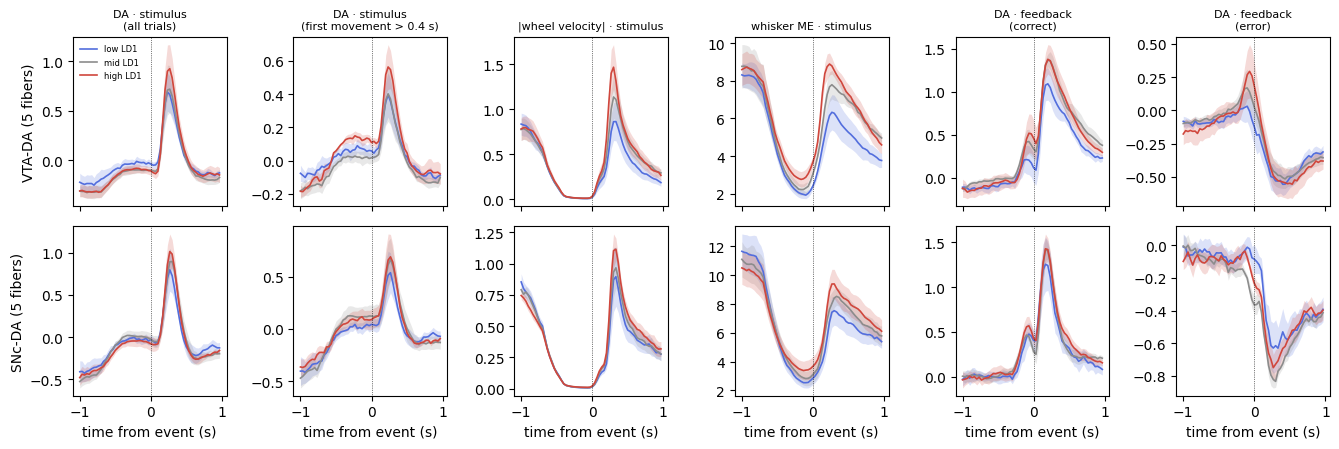

In [7]:
#%%
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import paper_style as ps
TR = L.traces(sorted(T['eid'].unique()))
PANELS = [('stim_all', 'DA · stimulus\n(all trials)'), ('stim_slow', 'DA · stimulus\n(first movement > 0.4 s)'),
          ('stim wheel speed', '|wheel velocity| · stimulus'), ('stim whisker ME', 'whisker ME · stimulus'),
          ('fb_correct', 'DA · feedback\n(correct)'), ('fb_error', 'DA · feedback\n(error)')]
BIN_COL = [ps.LD1_CMAP(0.08), '0.55', ps.LD1_CMAP(0.92)]
fig, axes = plt.subplots(2, len(PANELS), figsize=(2.25 * len(PANELS), 4.6), sharex=True)
for i, tg in enumerate(['VTA-DA', 'SNc-DA']):
    Tt = T[T['target_NM'] == tg]
    for j, (key, title) in enumerate(PANELS):
        ax = axes[i, j]
        t, out = L.binned_traces(Tt, TR, key)
        for b, (m, se) in out.items():
            ax.plot(t, m, color=BIN_COL[b], lw=1.2, label=['low', 'mid', 'high'][b] + ' LD1')
            ax.fill_between(t, m - se, m + se, color=BIN_COL[b], alpha=0.2, lw=0)
        ax.axvline(0, color='k', lw=0.5, ls=':')
        if i == 0:
            ax.set_title(title, fontsize=8)
        if j == 0:
            ax.set_ylabel(f"{tg} ({Tt['fiber'].nunique()} fibers)")
        if i == 1:
            ax.set_xlabel('time from event (s)')
axes[0, 0].legend(fontsize=6, frameon=False, loc='upper left')
plt.tight_layout()
pathlib.Path('figures').mkdir(exist_ok=True)
fig.savefig('figures/da_ld1_traces.png', dpi=250, bbox_inches='tight')
plt.show()

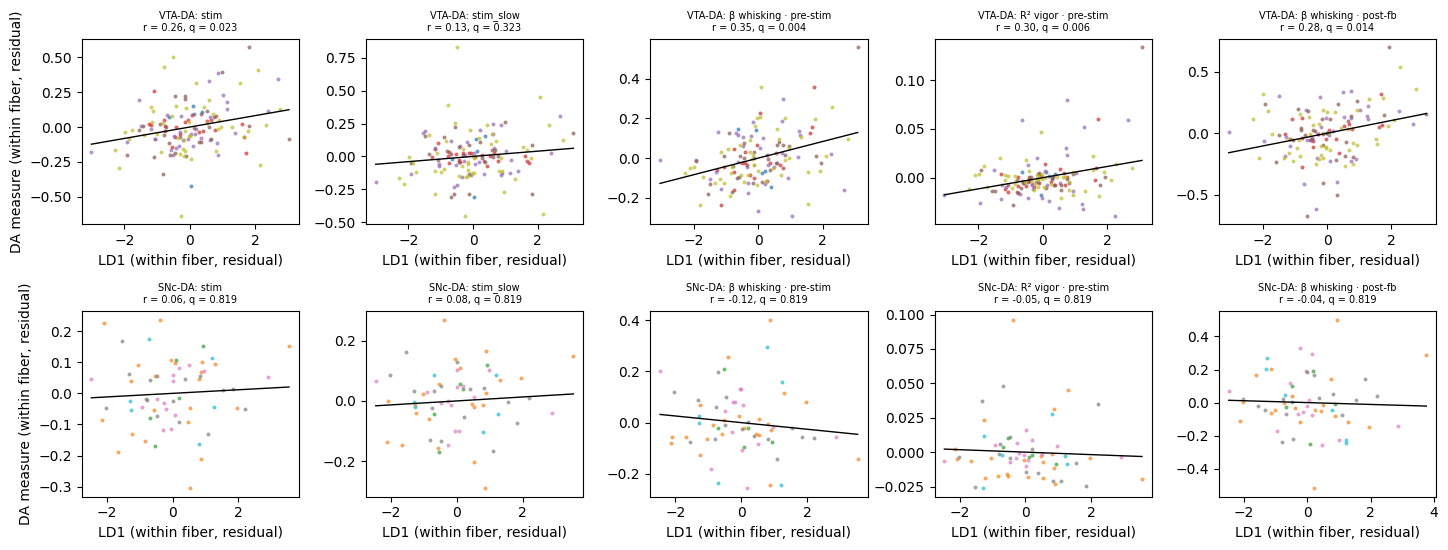

In [8]:
#%%
""" FIGURE: within-fiber residuals (day, protocol, RT, accuracy removed), sessions coloured by fiber; VTA top, SNc bottom """
def resid(d, cols, ctl):
    covs = [c for c in ctl if c not in ('day', 'protocol')]
    d = d[['fiber', 'day_n', 'protocol'] + list(dict.fromkeys(cols + covs))].replace([np.inf, -np.inf], np.nan).dropna()
    F = pd.get_dummies(d['fiber']).to_numpy(float)
    day = F * (d['day_n'] - d.groupby('fiber')['day_n'].transform('mean')).to_numpy()[:, None]
    D = np.column_stack([F, day, (d['protocol'] == 'ephys').to_numpy(float)] + [d[c].to_numpy(float) for c in covs])
    return d.assign(**{c: d[c] - D @ np.linalg.lstsq(D, d[c].to_numpy(float), rcond=None)[0] for c in cols})

SHOW = ['stim', 'stim_slow', 'R² vigor · pre-stim', 'β whisking · post-fb']
ctl = STEPS['+ RT + accuracy']
fibers = sorted(T['fiber'].unique())
cmap = dict(zip(fibers, plt.cm.tab10(np.arange(len(fibers)))))
SHOW = ['stim', 'stim_slow', 'β whisking · pre-stim', 'R² vigor · pre-stim', 'β whisking · post-fb']
fig, AX = plt.subplots(2, len(SHOW), figsize=(2.9 * len(SHOW), 5.6))
for row, tg in zip(AX, ['VTA-DA', 'SNc-DA']):
  for ax, y in zip(row, SHOW):
    d = resid(T[T['target_NM'] == tg], ['LD1', y], ctl)
    for f, g in d.groupby('fiber'):
        ax.scatter(g['LD1'], g[y], s=8, color=cmap[f], alpha=.7, lw=0)
    b = np.polyfit(d['LD1'], d[y], 1)
    xx = np.linspace(d['LD1'].min(), d['LD1'].max(), 10)
    ax.plot(xx, np.polyval(b, xx), color='k', lw=1)
    r = PER[tg]['+ RT + accuracy'].loc[y]
    ax.set_title(f"{tg}: {y}\nr = {r['r']:.2f}, q = {r['q']:.3f}", fontsize=7)
    ax.set_xlabel('LD1 (within fiber, residual)')
  row[0].set_ylabel('DA measure (within fiber, residual)')
plt.tight_layout(); plt.show()

## Reading

- **Session LD1 is a meaningful within-mouse variable**: within DA fibers it tracks the same session's RT
  (r ≈ −0.57), accuracy (+0.21) and movement gating, and is unrelated to recording day.
- **VTA and SNc behave differently, so they are read separately.** The LD1 × target interaction is significant for
  whisking coupling before the stimulus (q = 0.02) and nominal (p < 0.05) for vigor R² before / after the stimulus
  and whisking coupling after feedback.
- **VTA** (5 fibers, 135 sessions; RT, accuracy, day and protocol controlled):
  - **coupling**: in high-LD1 sessions VTA DA follows movement more: whisking β before the stimulus +0.35
    (q = 0.007), after feedback +0.28 (q = 0.01), unique vigor R² before the stimulus +0.30 (q = 0.007);
  - **stimulus response** +0.26 (q = 0.02), but on trials whose movement comes after the window only +0.13 (n.s.):
    mostly movement-locked DA (the traces: high-LD1 sessions move more right after the stimulus, wheel and whisker);
  - **feedback**: the traces show a larger response to correct feedback at high LD1, but it comes with a higher DA
    level just before feedback; the baseline-corrected reward measure does not move with LD1 (n.s.). Error dips:
    explained by RT.
- **SNc** (5 fibers, 63 sessions): nothing tracks LD1 (all q ≥ 0.27); in the traces the three LD1 bins overlap.
- **Baseline** (pooled −0.26) is explained by RT in both.

So: within mice, high-LD1 sessions are sessions in which **VTA** DA is more coupled to movement (whisking above all)
and responds more around the stimulus, largely because the mouse moves more then; SNc DA is unchanged. Caveat: an R²
can grow with movement variance; controlling quiescence wheel speed covers part of that. Next: trial-level models
(DA ~ movement + task, session LD1 as a moderator), and the other neuromodulators (ACh: `5_ach_ld1_within_mouse`).